# Visualize output of inference

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import time

file_name = "../output/test.txt"
num_adaptive_iter = 5000
burn_in = 5000

In [2]:
import numpy as np
from scipy.optimize import root_scalar
from scipy.interpolate import interp1d

# autocorrelation function
def autocorrelation(signal):
    x = np.array(signal) 

    # Normalized data
    ndata = x - np.mean(x)
    N = len(ndata)

    # Variance
    var = np.var(x)

    acorr = np.correlate(ndata, ndata, 'full')[N-1:] 
    return acorr / (N * var)

# root finder
def find_period(autocorr, tol=1e-6, max_iter=1000):

    interp_func = interp1d(np.arange(len(autocorr)), autocorr, kind='linear')
    end = np.where(autocorr < 0)[0][0]

    if interp_func(0) * interp_func(end) >= 0:
        raise ValueError("The function values at the interval endpoints must have opposite signs.")

    result = root_scalar(interp_func, bracket=[0, end], method='bisect', xtol=tol)

    if result.converged:
        return result.root
    else:
        raise Exception("Root finding did not converge.")
    
# compute mean and standard deviation from uncorrelated samples
def mcmc_mean(data) :
    autocorr = autocorrelation(data)
    period = np.round(find_period(autocorr)).astype(int)

    return [data[::-period].mean(), data[::-period].std(ddof=1)]

## Results visualization

Text(0.5, 0, 'N. of iterations')

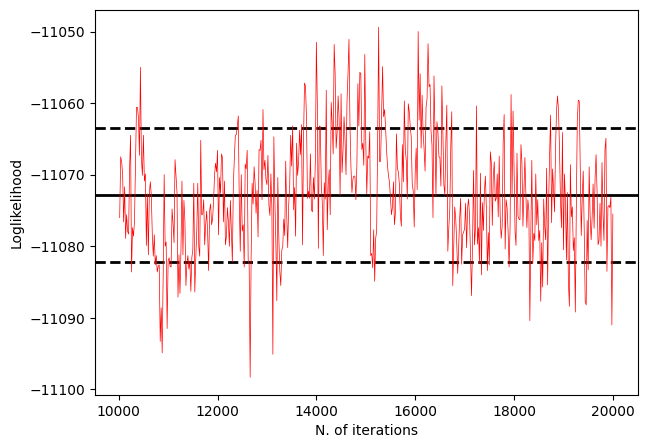

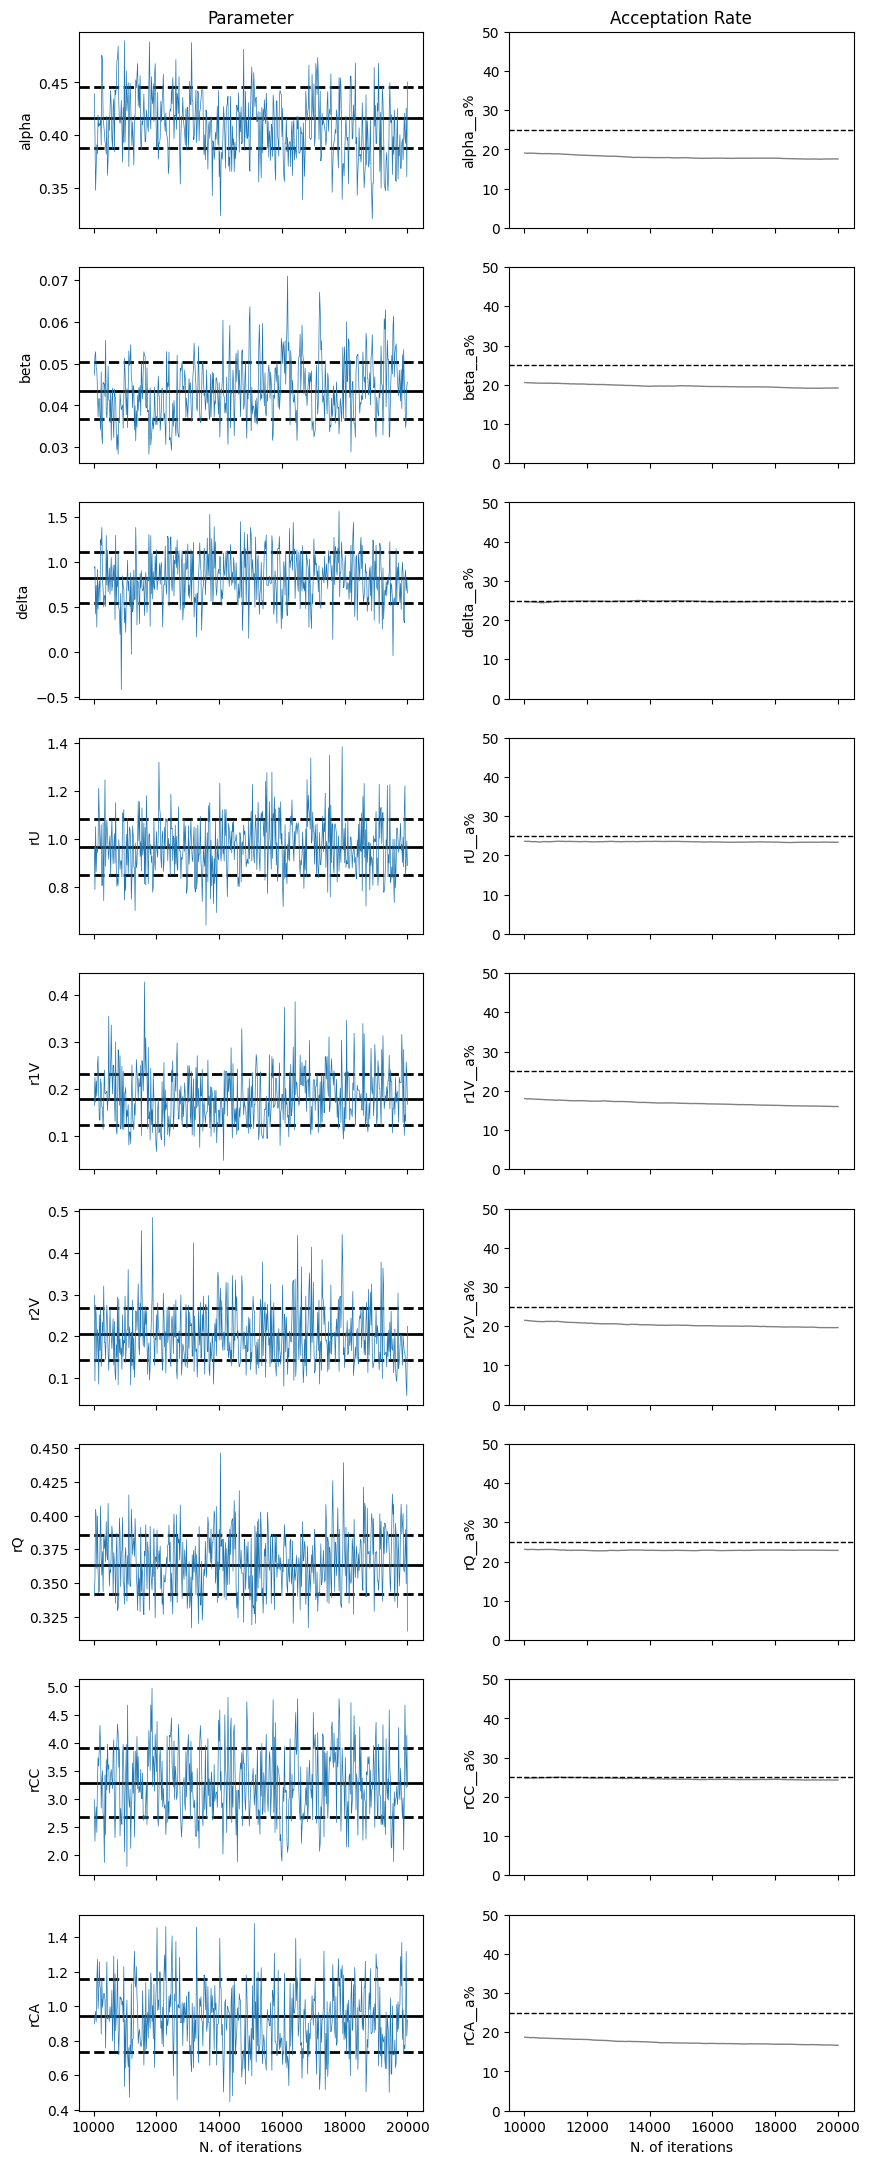

In [3]:
results = pd.read_csv(file_name, sep=" ", index_col="iter")
df = results[results.index > num_adaptive_iter+burn_in]
cols = df.columns.to_list()
cols.remove('loglike')
param_names = [c for c in cols if "__a%" not in c]

thinning = df.index[1] - df.index[0]

plt.figure(figsize=(7,5))

mu, sigma = mcmc_mean(df["loglike"])
plt.axhline(y=mu, color="black", lw=2, ls="-")
plt.axhline(y=mu-sigma, color="black", lw=2, ls="--")
plt.axhline(y=mu+sigma, color="black", lw=2, ls="--")

plt.plot(df["loglike"], color = "red", lw=0.5)

plt.xlabel("N. of iterations")
plt.ylabel("Loglikelihood")

fig, axes = plt.subplots(figsize=(10, 3 * len(param_names)),
                        nrows=len(param_names), ncols=2, sharex=True)
fig.subplots_adjust(wspace=0.25)

for i, p in enumerate(param_names) :
    mu, sigma = mcmc_mean(df[p])
    axes[i, 0].axhline(y=mu, color="black", lw=2, ls="-")
    axes[i, 0].axhline(y=mu-sigma, color="black", lw=2, ls="--")
    axes[i, 0].axhline(y=mu+sigma, color="black", lw=2, ls="--")

    axes[i, 0].plot(df.index, df[p], label=p, lw=0.5)
    axes[i, 0].set_ylabel(p)

    axes[i, 1].plot(df.index, df[f"{p}__a%"], label=p, lw=1, color="grey")
    axes[i, 1].set_ylabel(f"{p}__a%")
    #axes[i, 0].set_yscale("log")
    #xes[i, 1].set_xscale("log")
    axes[i, 1].set_ylim([0, 50])
    axes[i, 1].axhline(y=25, ls="--", lw=1, color='black')

axes[0, 0].set_title("Parameter")
axes[0, 1].set_title("Acceptation Rate")
axes[-1, 0].set_xlabel("N. of iterations")
axes[-1, 1].set_xlabel("N. of iterations")

# Autocorrelation functions

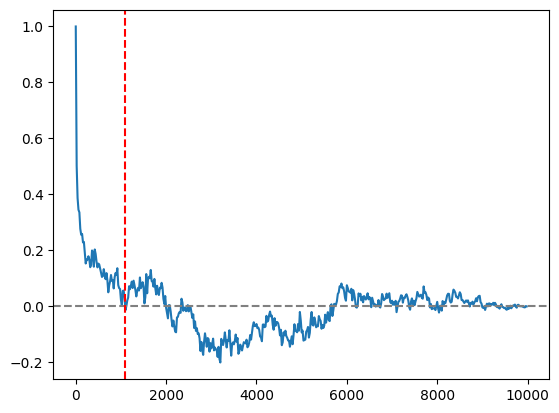

In [4]:
data = df["loglike"]
thinning = df.index[1] - df.index[0]

iterations = thinning * np.arange(len(data))
autocorr = autocorrelation(data)
period = np.round(find_period(autocorr)).astype(int)

plt.figure()
plt.plot(iterations, autocorr)
plt.axhline(y=0, color="grey", ls = "--")
plt.axvline(x=thinning * period, color="red", ls="--")